# Putative neuronal populations

Classification and three-dimensional visualization of putative fast-spiking interneurons (FSIs), unidentified interneurons (UINs), medium spiny neurons (MSNs), and tonically active neurons (TANs).

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np

## Load the data

In [2]:
# Locate the data file whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (path for path in project_candidates if (path / "data" / "NAC" / "1468.pkl").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate data/NAC/1468.pkl from the current directory.")

data_file = project_root / "data" / "NAC" / "1468.pkl"

# The pickle contains twelve arrays in a fixed order. Only the arrays required
# for this figure are used below; the remaining arrays are loaded to preserve
# the original serialized-data layout.
with data_file.open("rb") as stream:
    half_width = pickle.load(stream)
    proportion_long_isi = pickle.load(stream)
    post_spike_suppression = pickle.load(stream)
    animal_id = pickle.load(stream)
    shank_id = pickle.load(stream)
    unit_id = pickle.load(stream)
    spike_duration_s = pickle.load(stream)
    mean_firing_rate = pickle.load(stream)
    secondary_firing_rate = pickle.load(stream)
    spike_times = pickle.load(stream)
    autocorrelations = pickle.load(stream)
    waveforms = pickle.load(stream)

print(f"Loaded {spike_duration_s.shape[0]} units from {data_file.name}.")

Loaded 1468 units from 1468.pkl.


## Classify putative neuronal populations

The thresholds below reproduce the original classification criteria without modification.

In [3]:
# Convert spike duration from seconds to microseconds for classification
# and display. These four masks retain the original thresholds exactly.
spike_duration_us = spike_duration_s * 1_000_000

is_fsi = (spike_duration_us <= 400) & (proportion_long_isi <= 0.1)
is_uin = (spike_duration_us <= 400) & (proportion_long_isi > 0.1)
is_msn = (spike_duration_us > 400) & (post_spike_suppression < 40)
is_tan = (spike_duration_us > 400) & (post_spike_suppression >= 40)

population_masks = {
    "FSI": is_fsi,
    "UIN": is_uin,
    "MSN": is_msn,
    "TAN": is_tan,
}

# Confirm that every unit belongs to exactly one population.
membership_count = sum(mask.astype(int) for mask in population_masks.values())
if not np.all(membership_count == 1):
    raise ValueError("The population masks are not mutually exclusive and exhaustive.")

for population, mask in population_masks.items():
    print(f"{population}: {np.count_nonzero(mask)} units")

FSI: 57 units
UIN: 57 units
MSN: 1211 units
TAN: 143 units


## Plot the putative populations

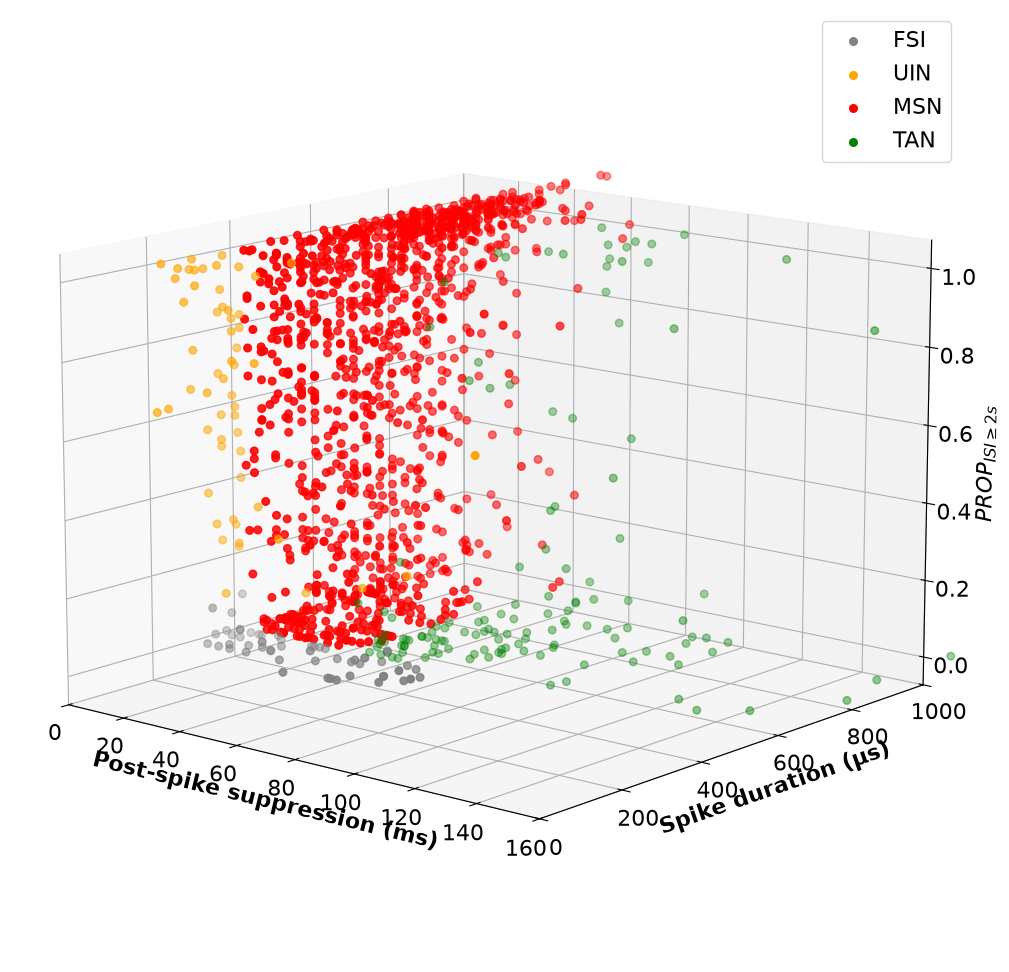

In [4]:
population_colors = {
    "FSI": "gray",
    "UIN": "orange",
    "MSN": "red",
    "TAN": "green",
}

plt.rcParams.update({"font.size": 16})
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection="3d")

for population, mask in population_masks.items():
    ax.scatter3D(
        post_spike_suppression[mask],
        spike_duration_us[mask],
        proportion_long_isi[mask],
        s=30,
        label=population,
        color=population_colors[population],
    )

ax.set_xlim(0, 160)
ax.set_ylim(0, 1000)
ax.set_xlabel("Post-spike suppression (ms)", fontweight="bold")
ax.set_ylabel("Spike duration (µs)", fontweight="bold")
ax.set_zlabel(r"$PROP_{ISI \geq 2 s}$", fontweight="bold")
ax.view_init(13, -50)
ax.legend()
plt.tight_layout()
plt.show()